In [1]:
import sys

print("Python version:",sys.version)
print("Python executable:",sys.executable)

Python version: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
Python executable: c:\Users\ASUS\anaconda3\envs\pytorch-learning\python.exe


In [4]:
import pyvista as pv

print("PyVista version:",pv.__version__)
print("Installation successful!")

PyVista version: 0.49.3
Installation successful!


In [2]:
from pyvista import examples

data = examples.download_electronics_cooling()

print(type(data))

<class 'pyvista.core.composite.MultiBlock'>


In [3]:
structure=data["structure"]
air=data["air"]

print("Structure:",type(structure))
print("Air:",type(air))

Structure: <class 'pyvista.core.pointset.PolyData'>
Air: <class 'pyvista.core.pointset.UnstructuredGrid'>


In [11]:
for name,mesh in [("STRUCTURE",structure),("AIR",air)]:

    print("\n==========",name,"==========")

    print("Type:",type(mesh))
    print("Number of points:",mesh.n_points)
    print("Number of cells:",mesh.n_cells)
    print("Bounds:",mesh.bounds)
    print("Array names:",mesh.array_names)


========== STRUCTURE ==========
Type: <class 'pyvista.core.pointset.PolyData'>
Number of points: 187992
Number of cells: 344270
Bounds: BoundsTuple(x_min = -0.003000000026077032,
            x_max =  0.15299999713897705,
            y_min = -0.003000000026077032,
            y_max =  0.2029999941587448,
            z_min = -0.008999999612569809,
            z_max =  0.041999999433755875)
Array names: ['T', 'wallHeatFlux', 'T', 'wallHeatFlux']

========== AIR ==========
Type: <class 'pyvista.core.pointset.UnstructuredGrid'>
Number of points: 610176
Number of cells: 1749992
Bounds: BoundsTuple(x_min = -1.387778801460961e-18,
            x_max =  0.15000000596046448,
            y_min = -0.003000000026077032,
            y_max =  0.2029999941587448,
            z_min = -0.006000000052154064,
            z_max =  0.04399999976158142)
Array names: ['p', 'Nu', 'T', 'U', 'alphat', 'heatTransferCoeff', 'k', 'nut', 'omega', 'wallHeatFlux']


In [8]:
import numpy as np

for name,mesh in [("STRUCTURE",structure),("AIR",air)]:
    print("\n==========",name,"==========")

    for association in ["point_data","cell_data"]:
        arrays=getattr(mesh,association)

        for key in arrays.keys():
            values=np.asarray(arrays[key])

            print("\nField:",key)
            print("Location:",association)
            print("Shape:",values.shape)
            print("Minimum:",np.min(values))
            print("Maximum:",np.max(values))


========== STRUCTURE ==========

Field: T
Location: point_data
Shape: (187992,)
Minimum: 293.33252
Maximum: 410.43002

Field: wallHeatFlux
Location: point_data
Shape: (187992,)
Minimum: -34942.863
Maximum: 34942.863

Field: T
Location: cell_data
Shape: (344270,)
Minimum: 293.30618
Maximum: 410.43607

Field: wallHeatFlux
Location: cell_data
Shape: (344270,)
Minimum: -39006.6
Maximum: 39006.6

========== AIR ==========

Field: Nu
Location: point_data
Shape: (610176,)
Minimum: 0.0
Maximum: 41577.492

Field: T
Location: point_data
Shape: (610176,)
Minimum: 293.0
Maximum: 410.43002

Field: U
Location: point_data
Shape: (610176, 3)
Minimum: -5.525419
Maximum: 4.914275

Field: alphat
Location: point_data
Shape: (610176,)
Minimum: 0.0
Maximum: 0.00071866263

Field: heatTransferCoeff
Location: point_data
Shape: (610176,)
Minimum: 0.0
Maximum: 1071.4321

Field: k
Location: point_data
Shape: (610176,)
Minimum: 7.093333e-11
Maximum: 0.8229905

Field: nut
Location: point_data
Shape: (610176,)
Mini

In [9]:
import pandas as pd
import numpy as np

results=[]

for name,mesh in [("STRUCTURE",structure),("AIR",air)]:
    for location in ["point_data","cell_data"]:
        arrays=getattr(mesh,location)

        for field in arrays.keys():
            values=np.asarray(arrays[field])

            results.append({
                "Dataset":name,
                "Field":field,
                "Location":location,
                "Shape":values.shape,
                "Minimum":np.min(values),
                "Maximum":np.max(values)
            })

summary=pd.DataFrame(results)

display(summary)

,Dataset,Field,Location,Shape,Minimum,Maximum
0,STRUCTURE,T,point_data,"(187992,)",2.933325e+02,4.104300e+02
1,STRUCTURE,wallHeatFlux,point_data,"(187992,)",-3.494286e+04,3.494286e+04
2,STRUCTURE,T,cell_data,"(344270,)",2.933062e+02,4.104361e+02
3,STRUCTURE,wallHeatFlux,cell_data,"(344270,)",-3.900660e+04,3.900660e+04
4,AIR,Nu,point_data,"(610176,)",0.000000e+00,4.157749e+04
5,AIR,T,point_data,"(610176,)",2.930000e+02,4.104300e+02
6,AIR,U,point_data,"(610176, 3)",-5.525419e+00,4.914275e+00
7,AIR,alphat,point_data,"(610176,)",0.000000e+00,7.186626e-04
8,AIR,heatTransferCoeff,point_data,"(610176,)",0.000000e+00,1.071432e+03
9,AIR,k,point_data,"(610176,)",7.093333e-11,8.229905e-01


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\82156703.py:12: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show(screenshot="temperature_distribution.png")


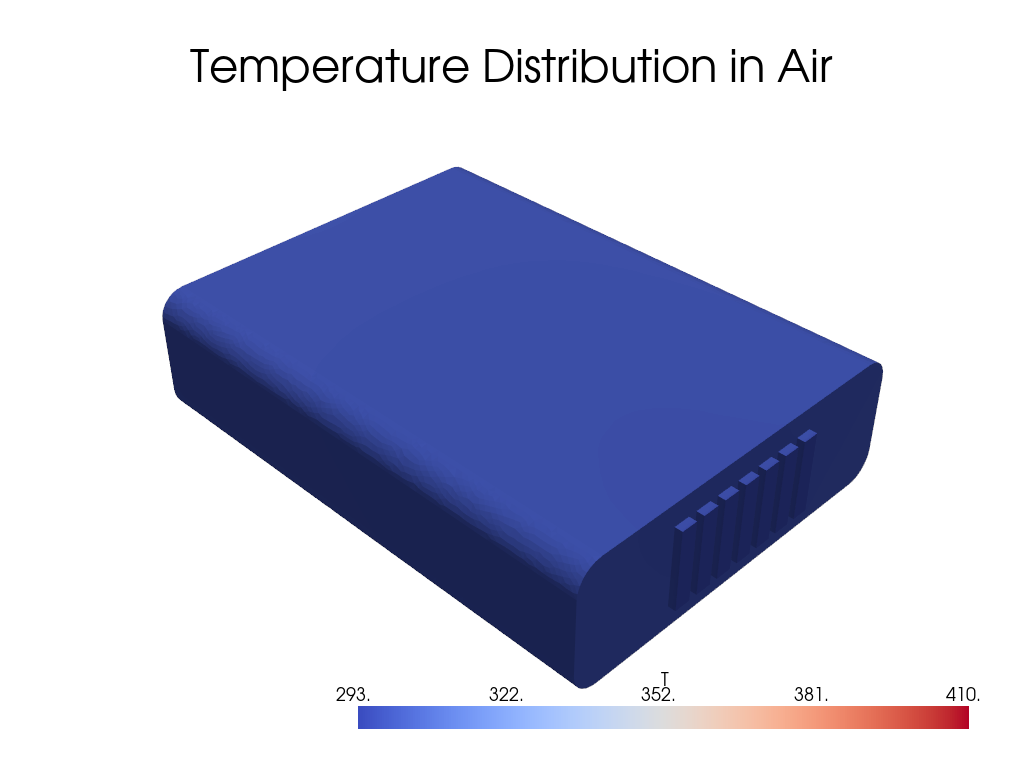

In [12]:
plotter=pv.Plotter()

plotter.add_mesh(
    air,
    scalars="T",
    cmap="coolwarm",
    show_scalar_bar=True
)

plotter.add_title("Temperature Distribution in Air")

plotter.show(screenshot="temperature_distribution.png")

In [13]:
velocity=air.point_data["U"]

velocity_magnitude=np.linalg.norm(velocity,axis=1)

air.point_data["Velocity_Magnitude"]=velocity_magnitude

print("Velocity magnitude shape:",velocity_magnitude.shape)
print("Minimum velocity:",velocity_magnitude.min())
print("Maximum velocity:",velocity_magnitude.max())

Velocity magnitude shape: (610176,)
Minimum velocity: 0.0
Maximum velocity: 5.5461216


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\2758009590.py:12: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show(screenshot="velocity_magnitude.png")


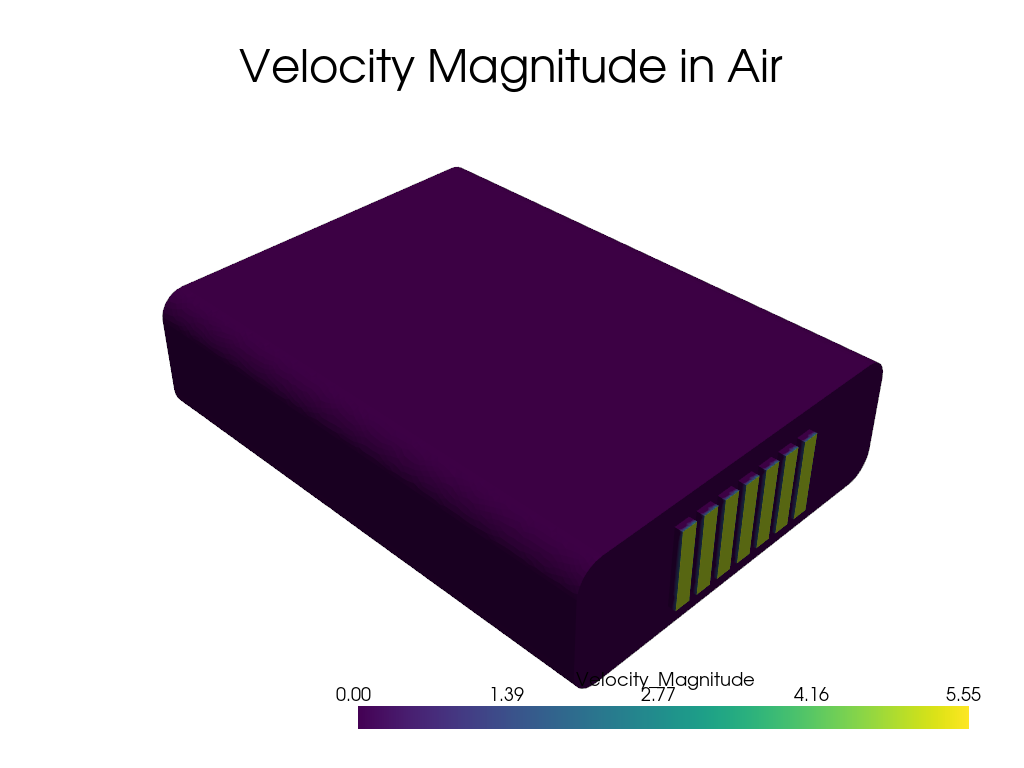

In [14]:
plotter=pv.Plotter()

plotter.add_mesh(
    air,
    scalars="Velocity_Magnitude",
    cmap="viridis",
    show_scalar_bar=True
)

plotter.add_title("Velocity Magnitude in Air")

plotter.show(screenshot="velocity_magnitude.png")

In [18]:
middle_slice=air.slice(
    normal="z",
    origin=(0,0,0.019)
)

print("Slice points:",middle_slice.n_points)
print("Slice cells:",middle_slice.n_cells)
print("Slice bounds:",middle_slice.bounds)

Slice points: 39317
Slice cells: 48088
Slice bounds: BoundsTuple(x_min =  0.0,
            x_max =  0.15000000596046448,
            y_min = -0.003000000026077032,
            y_max =  0.2029999941587448,
            z_min =  0.01899999938905239,
            z_max =  0.01899999938905239)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\1419799599.py:15: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


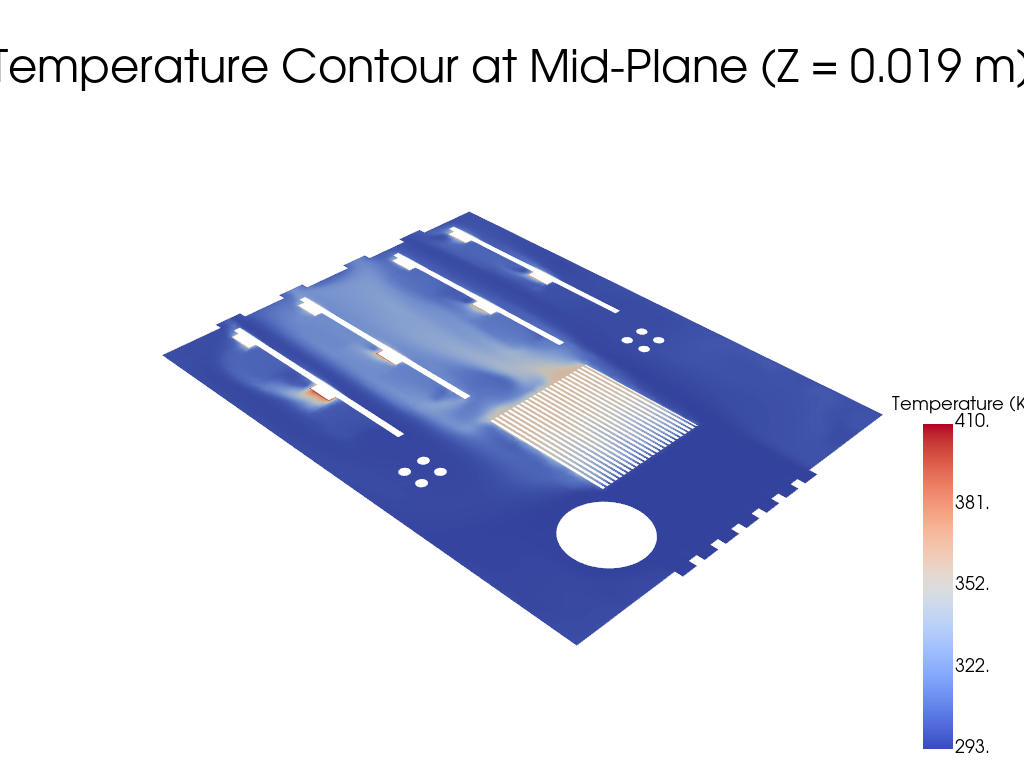

In [19]:
plotter=pv.Plotter()

plotter.add_mesh(
    middle_slice,
    scalars="T",
    cmap="coolwarm",
    scalar_bar_args={
        "title":"Temperature (K)",
        "vertical":True
    }
)

plotter.add_title("Temperature Contour at Mid-Plane (Z = 0.019 m)")

plotter.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\243520297.py:15: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


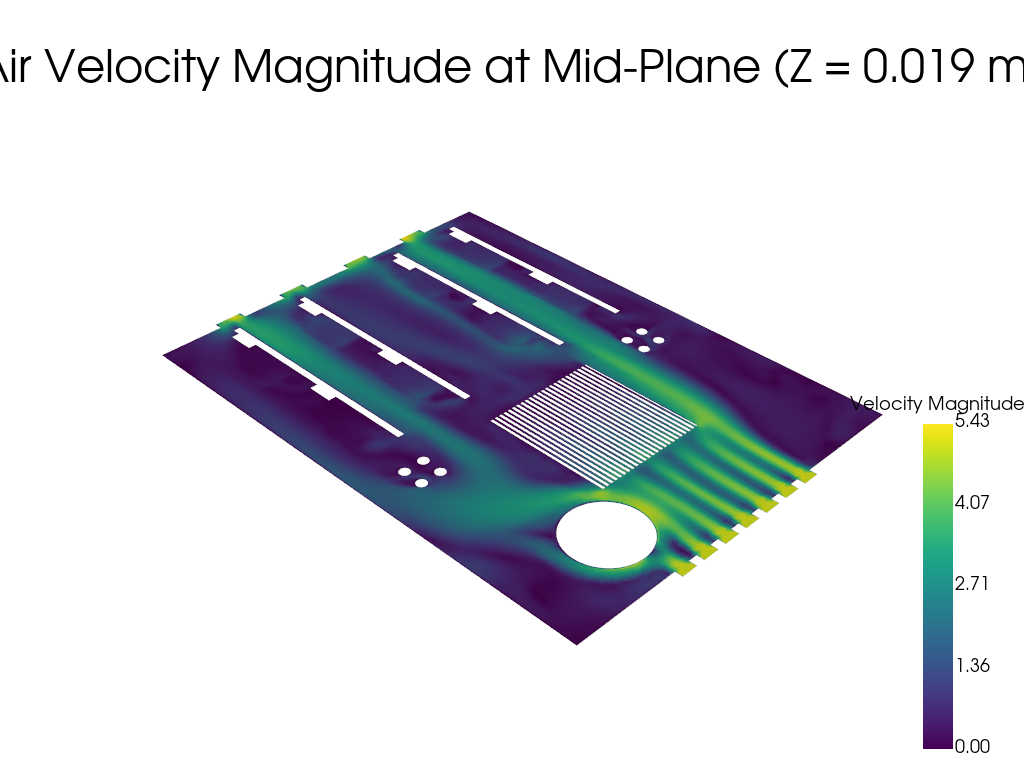

In [20]:
plotter=pv.Plotter()

plotter.add_mesh(
    middle_slice,
    scalars="Velocity_Magnitude",
    cmap="viridis",
    scalar_bar_args={
        "title":"Velocity Magnitude (m/s)",
        "vertical":True
    }
)

plotter.add_title("Air Velocity Magnitude at Mid-Plane (Z = 0.019 m)")

plotter.show()

In [21]:
clipped=air.clip(
    normal="x",
    origin=(0.075,0,0),
    invert=False
)

print("Original cells:",air.n_cells)
print("Clipped cells:",clipped.n_cells)
print("Clipped points:",clipped.n_points)
print("Clipped bounds:",clipped.bounds)

Original cells: 1749992
Clipped cells: 879979
Clipped points: 313123
Clipped bounds: BoundsTuple(x_min =  0.07500000298023224,
            x_max =  0.15000000596046448,
            y_min = -0.003000000026077032,
            y_max =  0.2029999941587448,
            z_min = -0.006000000052154064,
            z_max =  0.04399999976158142)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\990192633.py:14: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


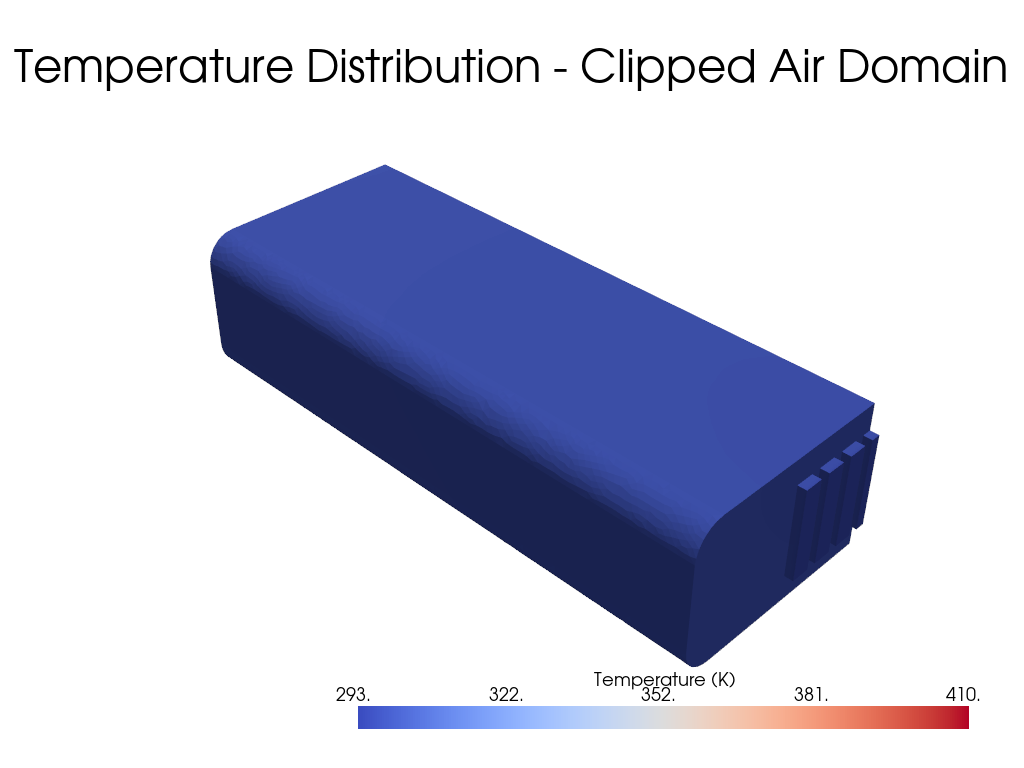

In [22]:
plotter=pv.Plotter()

plotter.add_mesh(
    clipped,
    scalars="T",
    cmap="coolwarm",
    scalar_bar_args={
        "title":"Temperature (K)"
    }
)

plotter.add_title("Temperature Distribution - Clipped Air Domain")

plotter.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\1018889866.py:20: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


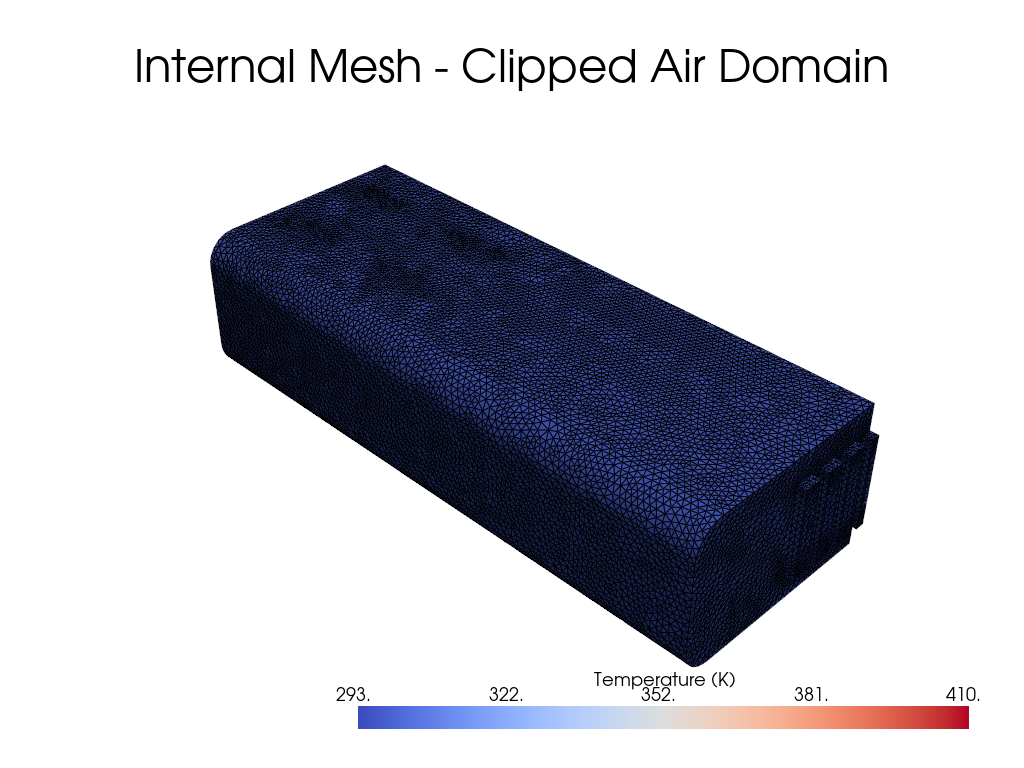

In [23]:
plotter=pv.Plotter()

plotter.add_mesh(
    clipped,
    scalars="T",
    cmap="coolwarm",
    show_edges=True,
    edge_color="black",
    line_width=0.15,
    scalar_bar_args={
        "title":"Temperature (K)"
    }
)

plotter.add_title(
    "Internal Mesh - Clipped Air Domain"
)

plotter.camera_position="iso"
plotter.show()

In [25]:
clipped_plane=clipped.slice(
    normal="x",
    origin=(0.076,0,0)
)

print("Points:",clipped_plane.n_points)
print("Cells:",clipped_plane.n_cells)
print("Bounds:",clipped_plane.bounds)

Points: 10360
Cells: 12448
Bounds: BoundsTuple(x_min =  0.07599999755620956,
            x_max =  0.07599999755620956,
            y_min =  0.0,
            y_max =  0.2029999941587448,
            z_min = -0.006000000052154064,
            z_max =  0.04399999976158142)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\629979270.py:17: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


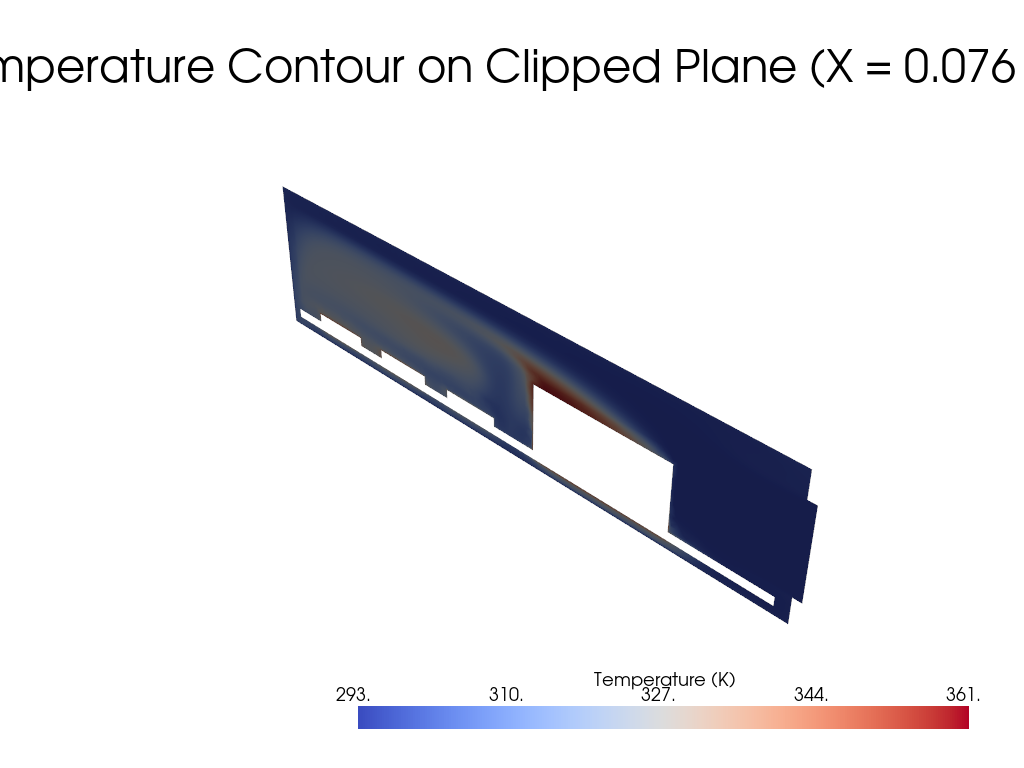

In [26]:
plotter=pv.Plotter()

plotter.add_mesh(
    clipped_plane,
    scalars="T",
    cmap="coolwarm",
    show_scalar_bar=True,
    scalar_bar_args={
        "title":"Temperature (K)"
    }
)

plotter.add_title(
    "Temperature Contour on Clipped Plane (X = 0.076 m)"
)

plotter.show()

In [27]:
structure_converted=structure.cell_data_to_point_data()

print("Original cell data:")
print(structure.cell_data.keys())

print("\nConverted point data:")
print(structure_converted.point_data.keys())

print("\nOriginal points:",structure.n_points)
print("Converted points:",structure_converted.n_points)


Original cell data:
['T', 'wallHeatFlux']

Converted point data:
['T', 'wallHeatFlux']

Original points: 187992
Converted points: 187992


In [28]:
print("Original cell temperature:")
print("Min:",structure.cell_data["T"].min())
print("Max:",structure.cell_data["T"].max())

print("\nConverted point temperature:")
print("Min:",structure_converted.point_data["T"].min())
print("Max:",structure_converted.point_data["T"].max())

Original cell temperature:
Min: 293.30618
Max: 410.43607

Converted point temperature:
Min: 293.33252
Max: 410.43222


In [29]:
print("Are original and converted point temperatures identical?")
print(np.allclose(structure.point_data["T"],structure_converted.point_data["T"]))

print("Maximum absolute difference:")
print(np.max(np.abs(structure.point_data["T"]-structure_converted.point_data["T"])))

Are original and converted point temperatures identical?
False
Maximum absolute difference:
25.20221


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\2644377103.py:11: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


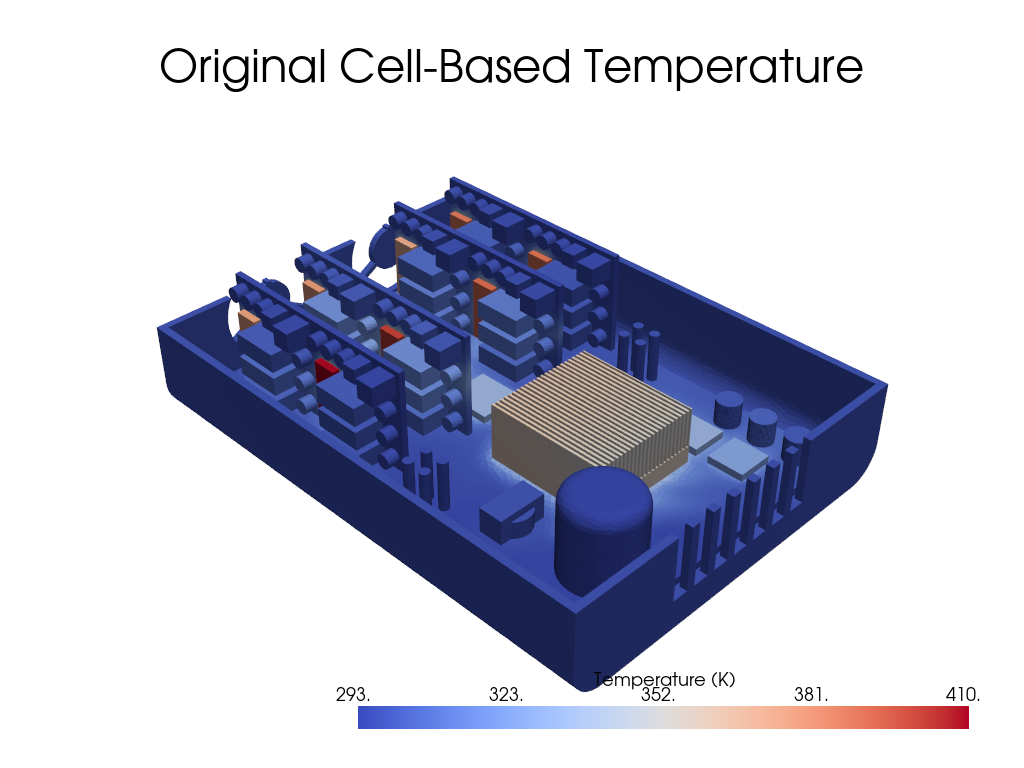

In [30]:
plotter=pv.Plotter()
plotter.add_mesh(
    structure,
    scalars="T",
    preference="cell",
    cmap="coolwarm",
    clim=[293.3,410.5],
    scalar_bar_args={"title":"Temperature (K)"}
)
plotter.add_title("Original Cell-Based Temperature")
plotter.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17128\789162364.py:11: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


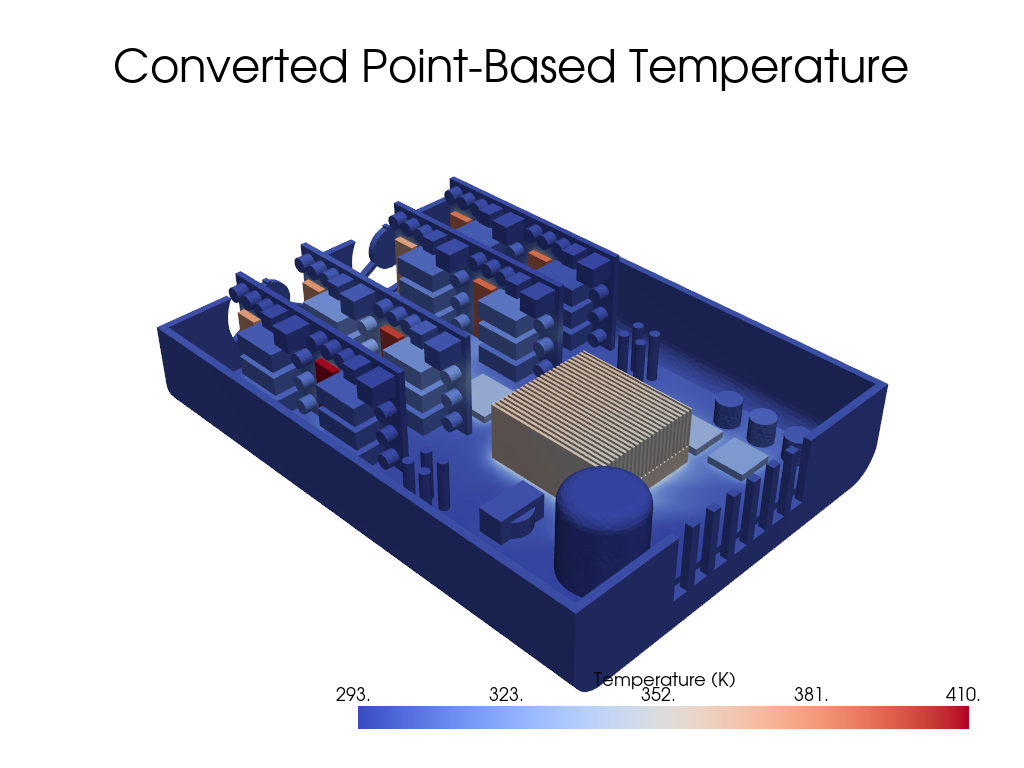

In [31]:
plotter=pv.Plotter()
plotter.add_mesh(
    structure_converted,
    scalars="T",
    preference="point",
    cmap="coolwarm",
    clim=[293.3,410.5],
    scalar_bar_args={"title":"Temperature (K)"}
)
plotter.add_title("Converted Point-Based Temperature")
plotter.show()

In [32]:
print(data)

MultiBlock (0x23370b5aaa0)
  N Blocks:   2
  X Bounds:   -3.000e-03, 1.530e-01
  Y Bounds:   -3.000e-03, 2.030e-01
  Z Bounds:   -9.000e-03, 4.400e-02


In [33]:
print("Air mesh type:",type(air))
print("Available point arrays:",air.point_data.keys())

Air mesh type: <class 'pyvista.core.pointset.UnstructuredGrid'>
Available point arrays: ['Nu', 'T', 'U', 'alphat', 'heatTransferCoeff', 'k', 'nut', 'omega', 'p', 'wallHeatFlux', 'Velocity_Magnitude']


In [34]:
coords=air.points

print("Coordinates shape:",coords.shape)
print("First 5 coordinates:")
print(coords[:5])

Coordinates shape: (610176, 3)
First 5 coordinates:
[[ 0.02206794  0.10780025  0.02187364]
 [ 0.0242703   0.11744162  0.00213732]
 [ 0.03792154  0.11478403 -0.00320486]
 [ 0.02498922  0.11140879  0.00883755]
 [ 0.00020478  0.11969789  0.00812774]]


In [35]:
fields={}

for name in air.point_data.keys():
    fields[name]=np.asarray(air.point_data[name])

print("Extracted fields:")
for name,values in fields.items():
    print(name,values.shape)

Extracted fields:
Nu (610176,)
T (610176,)
U (610176, 3)
alphat (610176,)
heatTransferCoeff (610176,)
k (610176,)
nut (610176,)
omega (610176,)
p (610176,)
wallHeatFlux (610176,)
Velocity_Magnitude (610176,)


In [36]:
case_data={"coords":coords}

case_data.update(fields)

print("Dictionary keys:")
print(case_data.keys())

Dictionary keys:
dict_keys(['coords', 'Nu', 'T', 'U', 'alphat', 'heatTransferCoeff', 'k', 'nut', 'omega', 'p', 'wallHeatFlux', 'Velocity_Magnitude'])


In [37]:
def load_case(path):
    mesh=pv.read(path)

    case_data={"coords":mesh.points}

    for name in mesh.point_data.keys():
        case_data[name]=np.asarray(mesh.point_data[name])

    return case_data

In [38]:
print(air)

UnstructuredGrid (0x23370fadc60)
  N Cells:    1749992
  N Points:   610176
  X Bounds:   -1.388e-18, 1.500e-01
  Y Bounds:   -3.000e-03, 2.030e-01
  Z Bounds:   -6.000e-03, 4.400e-02
  N Arrays:   11


In [39]:
air.save("air_mesh.vtu")

print("Air mesh saved successfully!")

Air mesh saved successfully!


In [40]:
loaded_data=load_case("air_mesh.vtu")

print("Loaded coordinates:",loaded_data["coords"].shape)
print("\nLoaded fields:")

for name,values in loaded_data.items():
    if name!="coords":
        print(name,values.shape)

Loaded coordinates: (610176, 3)

Loaded fields:
Nu (610176,)
T (610176,)
U (610176, 3)
alphat (610176,)
heatTransferCoeff (610176,)
k (610176,)
nut (610176,)
omega (610176,)
p (610176,)
wallHeatFlux (610176,)
Velocity_Magnitude (610176,)


In [41]:
np.savez("air_case_data.npz",**loaded_data)

print("Data saved successfully!")

Data saved successfully!


In [42]:

reloaded_data=np.load("air_case_data.npz")

print("Reloaded arrays:")

for name in reloaded_data.files:
    print(name,reloaded_data[name].shape)

Reloaded arrays:
coords (610176, 3)
Nu (610176,)
T (610176,)
U (610176, 3)
alphat (610176,)
heatTransferCoeff (610176,)
k (610176,)
nut (610176,)
omega (610176,)
p (610176,)
wallHeatFlux (610176,)
Velocity_Magnitude (610176,)


In [43]:
for name in loaded_data:
    print(name,np.allclose(loaded_data[name],reloaded_data[name]))

coords True
Nu True
T True
U True
alphat True
heatTransferCoeff True
k True
nut True
omega True
p True
wallHeatFlux True
Velocity_Magnitude True
